# 08 — Qiskit Machine Learning: quantum kernels, QNNs and hybrid PyTorch models

[Qiskit Machine Learning](https://qiskit-community.github.io/qiskit-machine-learning/) (QML) is a library of building blocks for quantum machine learning on top of Qiskit. It provides:

* **Quantum kernels** (`FidelityQuantumKernel`, `FidelityStatevectorKernel`, trainable kernels; [kernels API](https://qiskit-community.github.io/qiskit-machine-learning/apidocs/qiskit_machine_learning.kernels.html)). They work with scikit-learn style estimators such as `QSVC`.
* **Quantum neural networks (QNNs)** (`EstimatorQNN`, `SamplerQNN`; [neural networks API](https://qiskit-community.github.io/qiskit-machine-learning/apidocs/qiskit_machine_learning.neural_networks.html)). They have a forward pass and a backward pass (gradients).
* **Ready-made learners**: `VQC`, `VQR`, `NeuralNetworkClassifier` and `NeuralNetworkRegressor`.
* **`TorchConnector`** ([API](https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.connectors.TorchConnector.html)). It wraps a QNN as a `torch.nn.Module`, so the QNN can be one layer of a hybrid PyTorch model.

This notebook uses QML version **0.9.1** with Qiskit 2.x. All steps use the **V2 primitives** (`StatevectorSampler`, `StatevectorEstimator`, and the exact QML primitives `QMLSampler` and `QMLEstimator`, see the [primitives API](https://qiskit-community.github.io/qiskit-machine-learning/apidocs/qiskit_machine_learning.primitives.html)). The datasets are small (at most 40 samples and 3 features), so the notebook runs on a laptop CPU in a few minutes.

**Based on** (adapted from the official QML tutorials):

* [Quantum Kernel Machine Learning](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/03_quantum_kernel.html) (Sections 2–3)
* [Quantum Kernel Training for Machine Learning Applications](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/08_quantum_kernel_trainer.html) (Section 4)
* [Quantum Neural Networks](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/01_neural_networks.html) (Section 5)
* [Neural Network Classifier & Regressor](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/02_neural_network_classifier_and_regressor.html) (Sections 6–7)
* [Torch Connector and Hybrid QNNs](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/05_torch_connector.html) (Section 8)
* [Saving, Loading Qiskit Machine Learning Models and Continuous Training](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/09_saving_and_loading_models.html) (Section 9)

Install line (from `qiskit.def`):

```bash
pip install "qiskit-machine-learning[torch]"
```

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

import qiskit
import qiskit_machine_learning
import torch

from qiskit_machine_learning.utils import algorithm_globals

print("qiskit                 ", qiskit.__version__)
print("qiskit-machine-learning", qiskit_machine_learning.__version__)
print("torch                  ", torch.__version__)

SEED = 42
algorithm_globals.random_seed = SEED   # seeds QML's internal RNG (initial points, etc.)
np.random.seed(SEED)
torch.manual_seed(SEED)

qiskit                  2.5.2
qiskit-machine-learning 0.9.1
torch                   2.14.1+cu126


## 1. Data encoding with feature maps

A classical data point $\vec{x}$ must be loaded into a quantum state $|\phi(\vec{x})\rangle = U_{\phi}(\vec{x})|0\rangle$. The circuit $U_\phi$ is a **feature map**. The Qiskit circuit library has several feature maps (see the [`zz_feature_map` API reference](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.zz_feature_map)):

* `z_feature_map`: single-qubit rotations only. It creates no entanglement.
* `zz_feature_map`: adds $ZZ$ interactions with $\phi(x_i, x_j) = (\pi - x_i)(\pi - x_j)$. The features become entangled.
* `pauli_feature_map`: the general form, with arbitrary Pauli strings.

In Qiskit 2.x the preferred API is the lowercase **functions**, for example `zz_feature_map(...)`. They return a `QuantumCircuit`. The class form (`ZZFeatureMap`) still exists. It is a `BlueprintCircuit`, it is deprecated, and Qiskit 3.0 will remove it.

parameters: ParameterView([ParameterVectorElement(x[0]), ParameterVectorElement(x[1])])


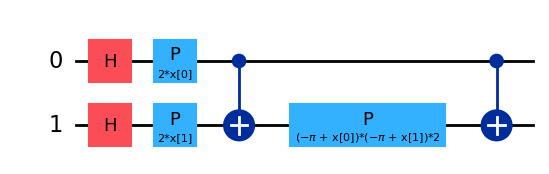

In [2]:
from qiskit.circuit.library import zz_feature_map, z_feature_map, real_amplitudes, efficient_su2

fm = zz_feature_map(feature_dimension=2, reps=1)
print("parameters:", fm.parameters)
fm.draw("mpl", fold=-1)

In [3]:
# Bind a concrete data point and look at the encoded state
from qiskit.quantum_info import Statevector

x = np.array([0.5, 1.2])
psi = Statevector(fm.assign_parameters(x))
print("amplitudes:", np.round(psi.data, 3))
print("probabilities:", np.round(psi.probabilities(), 3))

amplitudes: [ 0.5  +0.j     0.13 -0.483j  0.498+0.046j -0.483-0.128j]
probabilities: [0.25 0.25 0.25 0.25]


In [4]:
# The legacy class form still works, with a deprecation warning in Qiskit 2.x
from qiskit.circuit.library import ZZFeatureMap
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    fm_cls = ZZFeatureMap(2, reps=1)
    print("ZZFeatureMap depth:", fm_cls.decompose().depth())
    print("warnings:", sorted({x.category.__name__ for x in w}) or "none")
print("zz_feature_map depth:", fm.depth())

ZZFeatureMap depth: 5
warnings: ['DeprecationWarning']
zz_feature_map depth: 5


## 2. A small dataset: `ad_hoc_data`

[`ad_hoc_data`](https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.datasets.ad_hoc_data.html) generates the synthetic dataset of the [Quantum Kernel Machine Learning tutorial](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/03_quantum_kernel.html). Its labels are defined with a ZZ-type feature map, so a quantum kernel can separate the two classes perfectly. We use 2 features, 20 training points and 10 test points. Both classes have the same number of points.

train: (20, 2) test: (10, 2) classes: [0 1]


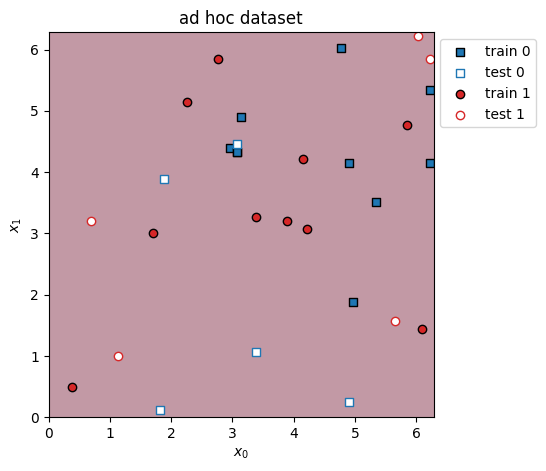

In [5]:
from qiskit_machine_learning.datasets import ad_hoc_data

X_train, y_train, X_test, y_test, adhoc_total = ad_hoc_data(
    training_size=10, test_size=5, n=2, gap=0.3, one_hot=False, include_sample_total=True
)
print("train:", X_train.shape, "test:", X_test.shape, "classes:", np.unique(y_train))

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(np.asmatrix(adhoc_total).T, interpolation="nearest", origin="lower",
          cmap="RdBu", extent=[0, 2 * np.pi, 0, 2 * np.pi], alpha=0.4)
for lab, mk, col in [(0, "s", "tab:blue"), (1, "o", "tab:red")]:
    ax.scatter(*X_train[y_train == lab].T, marker=mk, c=col, edgecolor="k", label=f"train {lab}")
    ax.scatter(*X_test[y_test == lab].T, marker=mk, facecolor="w", edgecolor=col, label=f"test {lab}")
ax.set_xlabel("$x_0$"); ax.set_ylabel("$x_1$"); ax.set_title("ad hoc dataset")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1));

## 3. Quantum kernels and QSVC

A **quantum kernel** is the overlap of two encoded states ([Quantum Kernel Machine Learning tutorial](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/03_quantum_kernel.html), [kernels API](https://qiskit-community.github.io/qiskit-machine-learning/apidocs/qiskit_machine_learning.kernels.html)):

$$K(\vec{x}, \vec{x}') = |\langle \phi(\vec{x}) | \phi(\vec{x}')\rangle|^2 .$$

QML has two implementations:

| class | how it computes $K$ | notes |
|---|---|---|
| `FidelityQuantumKernel` | a `BaseStateFidelity` object, by default `ComputeUncompute`. It runs $U_\phi^\dagger(\vec{x}')U_\phi(\vec{x})$ on a **V2 Sampler** and returns the probability of the outcome $|0\dots0\rangle$. | works with any sampler, including hardware |
| `FidelityStatevectorKernel` | classical statevectors | exact; fast for a few qubits; caches the statevectors |

Below we pass an explicit V2 sampler to `ComputeUncompute`. `QMLSampler()` is a subclass of `StatevectorSampler` in QML. With `shots=None` (the default) it returns exact probabilities. A plain `StatevectorSampler()` or a hardware `SamplerV2` gives estimates with shot noise.

In [6]:
from qiskit.primitives import StatevectorSampler, StatevectorEstimator
from qiskit_machine_learning.primitives import QMLSampler, QMLEstimator
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel, FidelityStatevectorKernel

adhoc_fm = zz_feature_map(feature_dimension=2, reps=2, entanglement="linear")

fidelity = ComputeUncompute(sampler=QMLSampler())            # exact V2 sampler
qkernel = FidelityQuantumKernel(feature_map=adhoc_fm, fidelity=fidelity)

sv_kernel = FidelityStatevectorKernel(feature_map=adhoc_fm)

K_train = qkernel.evaluate(x_vec=X_train)
K_test = qkernel.evaluate(x_vec=X_test, y_vec=X_train)
K_sv = sv_kernel.evaluate(x_vec=X_train)
print("K_train shape:", K_train.shape, " K_test shape:", K_test.shape)
print("max |FidelityQuantumKernel - FidelityStatevectorKernel| =", np.abs(K_train - K_sv).max())

# Shot-based estimate with a plain StatevectorSampler (1024 shots by default)
K_shots = FidelityQuantumKernel(
    feature_map=adhoc_fm, fidelity=ComputeUncompute(sampler=StatevectorSampler(seed=SEED))
).evaluate(x_vec=X_train)
print("max |shot-based - exact| =", np.abs(K_shots - K_sv).max().round(3))

K_train shape: (20, 20)  K_test shape: (10, 20)
max |FidelityQuantumKernel - FidelityStatevectorKernel| = 2.0007329126769946e-12


max |shot-based - exact| = 0.019


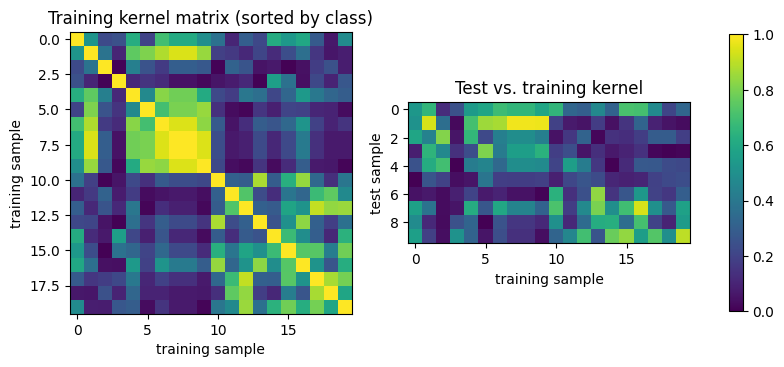

In [7]:
order = np.argsort(y_train)  # group by class to show the block structure
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
im = axs[0].imshow(K_train[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1)
axs[0].set_title("Training kernel matrix (sorted by class)")
axs[1].imshow(K_test[:, order], cmap="viridis", vmin=0, vmax=1)
axs[1].set_title("Test vs. training kernel")
for a in axs: a.set_xlabel("training sample")
axs[0].set_ylabel("training sample"); axs[1].set_ylabel("test sample")
fig.colorbar(im, ax=axs, shrink=0.8);

### QSVC

[`QSVC`](https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.algorithms.QSVC.html) extends the scikit-learn class `SVC` and takes a `quantum_kernel` argument. The precomputed kernel matrices can also go to a plain `SVC(kernel="precomputed")`. Both give the same result.

In [8]:
from sklearn.svm import SVC
from qiskit_machine_learning.algorithms import QSVC

qsvc = QSVC(quantum_kernel=qkernel)
qsvc.fit(X_train, y_train)
print("QSVC  train acc:", qsvc.score(X_train, y_train), " test acc:", qsvc.score(X_test, y_test))

svc = SVC(kernel="precomputed").fit(K_train, y_train)
print("SVC(precomputed) test acc:", svc.score(K_test, y_test))

qsvc_sv = QSVC(quantum_kernel=sv_kernel).fit(X_train, y_train)
print("QSVC (statevector kernel) test acc:", qsvc_sv.score(X_test, y_test))

QSVC  train acc: 1.0  test acc: 1.0
SVC(precomputed) test acc: 1.0
QSVC (statevector kernel) test acc: 1.0


## 4. Trainable quantum kernels (brief)

A **trainable kernel** adds free parameters $\vec\theta$ to the feature map. The kernel becomes $K_\theta(\vec x, \vec x')$. `QuantumKernelTrainer` tunes $\vec\theta$ to minimise a kernel loss ([Quantum Kernel Training tutorial](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/08_quantum_kernel_trainer.html)). The default loss is `"svc_loss"`, the SVC dual objective. Here we put one trainable $R_Y(\theta_i)$ layer before a ZZ feature map and run a few COBYLA iterations.

optimal θ: [3.507 2.744]  final loss: 5.046
QSVC with trained kernel, test acc: 1.0


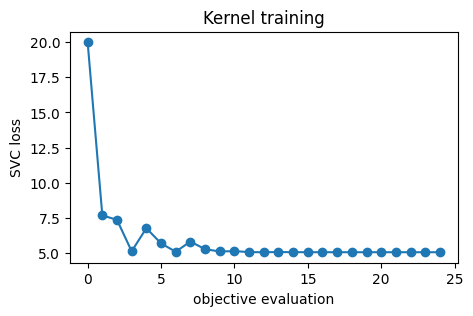

In [9]:
from qiskit.circuit import ParameterVector, QuantumCircuit
from qiskit_machine_learning.kernels import TrainableFidelityStatevectorKernel
from qiskit_machine_learning.kernels.algorithms import QuantumKernelTrainer
from qiskit_machine_learning.optimizers import COBYLA

theta = ParameterVector("θ", 2)
train_layer = QuantumCircuit(2)
for q in range(2):
    train_layer.ry(theta[q], q)
train_fm = train_layer.compose(zz_feature_map(2, reps=1))

tkernel = TrainableFidelityStatevectorKernel(feature_map=train_fm, training_parameters=theta)

from qiskit_machine_learning.utils.loss_functions import SVCLoss

loss_hist = []
class LoggedSVCLoss(SVCLoss):
    # SVCLoss that records every evaluation, for plotting
    def evaluate(self, parameter_values, quantum_kernel, data, labels):
        value = super().evaluate(parameter_values, quantum_kernel, data, labels)
        loss_hist.append(value)
        return value

qkt = QuantumKernelTrainer(
    quantum_kernel=tkernel, loss=LoggedSVCLoss(),
    optimizer=COBYLA(maxiter=25), initial_point=[np.pi / 2, np.pi / 2],
)
qkt_result = qkt.fit(X_train, y_train)
print("optimal θ:", np.round(qkt_result.optimal_point, 3), " final loss:", round(qkt_result.optimal_value, 3))

qsvc_t = QSVC(quantum_kernel=qkt_result.quantum_kernel).fit(X_train, y_train)
print("QSVC with trained kernel, test acc:", qsvc_t.score(X_test, y_test))

plt.figure(figsize=(5, 3)); plt.plot(loss_hist, "o-")
plt.xlabel("objective evaluation"); plt.ylabel("SVC loss"); plt.title("Kernel training");

## 5. Quantum neural networks: `EstimatorQNN` and `SamplerQNN`

A QNN is a parameterised circuit with two kinds of parameters ([Quantum Neural Networks tutorial](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/01_neural_networks.html)):

* **inputs**: the data, bound through the feature map;
* **weights**: the trainable parameters, bound through the ansatz.

QML has two QNN classes:

| QNN | primitive | output |
|---|---|---|
| `EstimatorQNN` | V2 Estimator | expectation values $\langle O_k\rangle$, shape `(batch, n_observables)` |
| `SamplerQNN` | V2 Sampler | (interpreted) measurement probabilities, shape `(batch, output_shape)` |

Both classes have `forward(input_data, weights)` and `backward(input_data, weights)`.

* `backward` returns `(input_grad, weight_grad)`. By default it uses the parameter-shift rule.
* `input_grad` is `None` unless you set `input_gradients=True`. `TorchConnector` needs this setting when gradients must reach earlier layers.

[`qnn_circuit`](https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.circuit.library.qnn_circuit.html) is a helper function. It composes a feature map with an ansatz and returns the circuit, the input parameters and the weight parameters.

inputs : [ParameterVectorElement(x[0]), ParameterVectorElement(x[1])]
weights: [ParameterVectorElement(θ[0]), ParameterVectorElement(θ[1]), ParameterVectorElement(θ[2]), ParameterVectorElement(θ[3])]


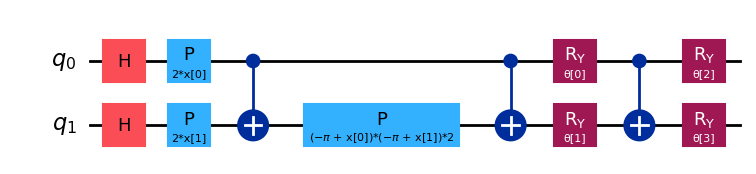

In [10]:
from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.circuit.library import qnn_circuit
from qiskit_machine_learning.neural_networks import EstimatorQNN, SamplerQNN

qc, input_params, weight_params = qnn_circuit(
    feature_map=zz_feature_map(2, reps=1), ansatz=real_amplitudes(2, reps=1)
)
print("inputs :", list(input_params))
print("weights:", list(weight_params))
qc.draw("mpl", fold=-1)

In [11]:
estimator = StatevectorEstimator(seed=SEED)
est_qnn = EstimatorQNN(
    circuit=qc,
    estimator=estimator,
    observables=SparsePauliOp("ZZ"),
    input_params=input_params,
    weight_params=weight_params,
    input_gradients=True,
)
x_in = algorithm_globals.random.random((3, est_qnn.num_inputs))
w = algorithm_globals.random.random(est_qnn.num_weights)

out = est_qnn.forward(x_in, w)
in_grad, w_grad = est_qnn.backward(x_in, w)
print("forward output shape:", out.shape, "\n", np.round(out, 4))
print("input  grad shape:", in_grad.shape)
print("weight grad shape:", w_grad.shape)

forward output shape: (3, 1) 
 [[ 0.1855]
 [-0.0601]
 [ 0.1283]]
input  grad shape: (3, 1, 2)
weight grad shape: (3, 1, 4)


> **Note on precision.** `EstimatorQNN` passes `precision=default_precision` (1/64 by default) to every `estimator.run` call. The Qiskit `StatevectorEstimator` reads a non-zero precision as a request to **add Gaussian noise** with that standard deviation. As a result, repeated forward passes give different numbers, even on a statevector simulator. For exact, deterministic results, pass `default_precision=0.0` or use `QMLEstimator()`, which is exact by default. The rest of this notebook uses `QMLEstimator`.

In [12]:
exact_qnn = EstimatorQNN(circuit=qc, estimator=QMLEstimator(), observables=SparsePauliOp("ZZ"),
                         input_params=input_params, weight_params=weight_params)
exact = exact_qnn.forward(x_in, w)

noisy_qnn = EstimatorQNN(circuit=qc, estimator=StatevectorEstimator(), observables=SparsePauliOp("ZZ"),
                         input_params=input_params, weight_params=weight_params)  # unseeded
n1, n2 = noisy_qnn.forward(x_in, w), noisy_qnn.forward(x_in, w)
print("StatevectorEstimator, precision 1/64: |run1 - exact| =", np.abs(n1 - exact).max().round(4),
      "  |run1 - run2| =", np.abs(n1 - n2).max().round(4))
print("QMLEstimator (exact):                 |run - exact|  =", np.abs(exact_qnn.forward(x_in, w) - exact).max())
# (est_qnn above used StatevectorEstimator(seed=42): its noise is reproducible, but still present)
print("seeded est_qnn vs exact:", np.abs(est_qnn.forward(x_in, w) - exact).max().round(4))

StatevectorEstimator, precision 1/64: |run1 - exact| = 0.016   |run1 - run2| = 0.0154
QMLEstimator (exact):                 |run - exact|  = 0.0
seeded est_qnn vs exact: 0.0162


In [13]:
sampler = StatevectorSampler(seed=SEED)  # shot-based V2 sampler (1024 shots)

def parity(bitstring_int):  # map a measured integer to a class index 0/1
    return bin(bitstring_int).count("1") % 2

samp_qnn = SamplerQNN(
    circuit=qc,
    sampler=sampler,
    input_params=input_params,
    weight_params=weight_params,
    interpret=parity,
    output_shape=2,
)
out = samp_qnn.forward(x_in, w)
_, w_grad = samp_qnn.backward(x_in, w)
print("forward (class probabilities):\n", np.round(out, 3))
print("rows sum to 1:", np.allclose(out.sum(axis=1), 1))
print("weight grad shape:", w_grad.shape, " (batch, outputs, weights)")

forward (class probabilities):
 [[0.582 0.418]
 [0.474 0.526]
 [0.559 0.441]]
rows sum to 1: True
weight grad shape: (3, 2, 4)  (batch, outputs, weights)


## 6. Variational classifier (`VQC`) and `NeuralNetworkClassifier`

The next dataset is 40 points from the scikit-learn function `make_moons` (2 features), scaled to $[0, \pi]$.

`VQC` (variational quantum classifier) is a convenience class ([`VQC` API](https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.algorithms.VQC.html), [Neural Network Classifier & Regressor tutorial](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/02_neural_network_classifier_and_regressor.html)). It takes a feature map and an ansatz. It then builds a `SamplerQNN` with parity interpretation and a one-hot cross-entropy loss. The optimiser calls `callback(weights, loss)` at each step, and we use it to record the training curve.

train (30, 2) test (10, 2)


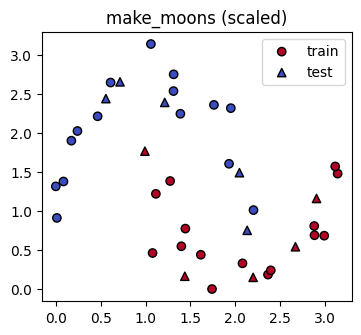

In [14]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

Xm, ym = make_moons(n_samples=40, noise=0.1, random_state=SEED)
Xm = MinMaxScaler(feature_range=(0, np.pi)).fit_transform(Xm)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.25, random_state=SEED, stratify=ym)
print("train", Xm_tr.shape, "test", Xm_te.shape)

plt.figure(figsize=(4, 3.5))
plt.scatter(*Xm_tr.T, c=ym_tr, cmap="coolwarm", edgecolor="k", label="train")
plt.scatter(*Xm_te.T, c=ym_te, cmap="coolwarm", marker="^", edgecolor="k", label="test")
plt.legend(); plt.title("make_moons (scaled)");

In [15]:
from qiskit_machine_learning.algorithms import VQC

vqc_loss = []
def vqc_callback(weights, loss):
    vqc_loss.append(loss)

vqc = VQC(
    feature_map=z_feature_map(2, reps=2),
    ansatz=efficient_su2(2, reps=2),
    optimizer=COBYLA(maxiter=100),
    sampler=QMLSampler(),         # exact V2 sampler -> smooth loss
    callback=vqc_callback,
)
vqc.fit(Xm_tr, ym_tr)
print("VQC train acc:", vqc.score(Xm_tr, ym_tr), " test acc:", vqc.score(Xm_te, ym_te))

VQC train acc: 0.8333333333333334  test acc: 0.8


### `NeuralNetworkClassifier` with a custom QNN

`NeuralNetworkClassifier` trains *any* QML neural network ([`NeuralNetworkClassifier` API](https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.algorithms.NeuralNetworkClassifier.html)). Here the network is an `EstimatorQNN`. Its output $\langle Z Z\rangle \in [-1, 1]$ is the decision function. We map the labels to $\{-1, +1\}$ and use `loss="squared_error"`. The predicted class is the sign of the output.

NNC train acc: 0.8666666666666667  test acc: 0.7


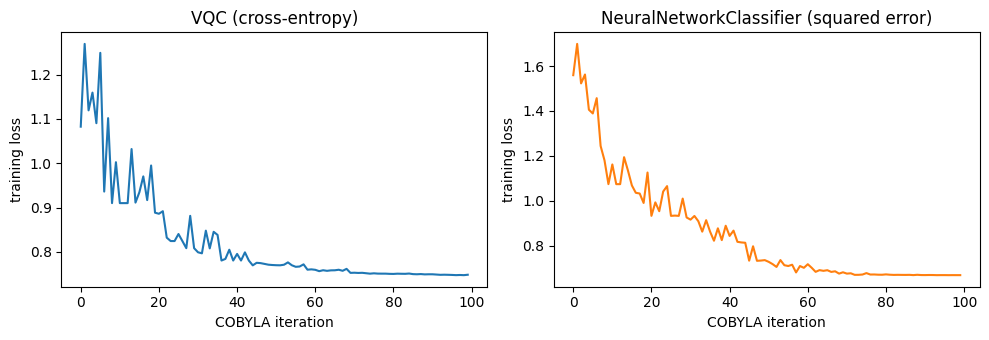

In [16]:
from qiskit_machine_learning.algorithms import NeuralNetworkClassifier

qc_c, ip_c, wp_c = qnn_circuit(feature_map=z_feature_map(2, reps=2), ansatz=efficient_su2(2, reps=2))
clf_qnn = EstimatorQNN(circuit=qc_c, estimator=QMLEstimator(),
                       observables=SparsePauliOp("ZZ"), input_params=ip_c, weight_params=wp_c)

nnc_loss = []
nnc = NeuralNetworkClassifier(
    neural_network=clf_qnn,
    loss="squared_error",
    optimizer=COBYLA(maxiter=100),
    callback=lambda w, l: nnc_loss.append(l),
)
ym_tr_pm, ym_te_pm = 2 * ym_tr - 1, 2 * ym_te - 1
nnc.fit(Xm_tr, ym_tr_pm)
print("NNC train acc:", nnc.score(Xm_tr, ym_tr_pm), " test acc:", nnc.score(Xm_te, ym_te_pm))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(vqc_loss); axs[0].set_title("VQC (cross-entropy)")
axs[1].plot(nnc_loss, color="tab:orange"); axs[1].set_title("NeuralNetworkClassifier (squared error)")
for a in axs: a.set_xlabel("COBYLA iteration"); a.set_ylabel("training loss")
plt.tight_layout();

## 7. Variational regression (`VQR`)

`VQR` (variational quantum regressor) is the regression version of `VQC` ([`VQR` API](https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.algorithms.VQR.html)). It wraps an `EstimatorQNN` with one observable (by default $Z^{\otimes n}$) and a squared-error loss.

We fit a noisy sine function on 20 one-dimensional points. The model uses one qubit, an $R_Y(x)$ encoding and an $R_Y(\theta)$ ansatz.

VQR R^2 score: 0.933  θ* = [-1.563]


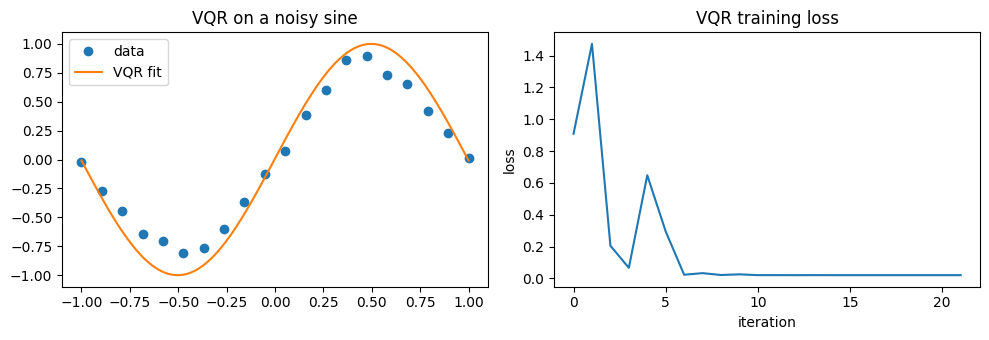

In [17]:
from qiskit.circuit import Parameter
from qiskit_machine_learning.algorithms import VQR

lb, ub = -1.0, 1.0
Xr = np.linspace(lb, ub, 20).reshape(-1, 1)
yr = np.sin(np.pi * Xr[:, 0]) * 0.8 + 0.05 * algorithm_globals.random.standard_normal(20)

xp, tp = Parameter("x"), Parameter("θ")
fm_r = QuantumCircuit(1); fm_r.ry(xp * np.pi, 0)
an_r = QuantumCircuit(1); an_r.ry(tp, 0)

vqr_loss = []
vqr = VQR(feature_map=fm_r, ansatz=an_r, optimizer=COBYLA(maxiter=40),
          estimator=QMLEstimator(), callback=lambda w, l: vqr_loss.append(l))
vqr.fit(Xr, yr)
print("VQR R^2 score:", round(vqr.score(Xr, yr), 3), " θ* =", np.round(vqr.weights, 3))

xs = np.linspace(lb, ub, 100).reshape(-1, 1)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(Xr, yr, "o", label="data"); axs[0].plot(xs, vqr.predict(xs), label="VQR fit")
axs[0].legend(); axs[0].set_title("VQR on a noisy sine")
axs[1].plot(vqr_loss); axs[1].set_xlabel("iteration"); axs[1].set_ylabel("loss"); axs[1].set_title("VQR training loss")
plt.tight_layout();

## 8. Hybrid models with `TorchConnector`

`TorchConnector(qnn, initial_weights)` turns a QNN into a `torch.nn.Module` ([Torch Connector and Hybrid QNNs tutorial](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/05_torch_connector.html)).

* The QNN weights become a `torch.nn.Parameter`.
* PyTorch autograd calls `qnn.backward` to get the gradients.
* Here the quantum layer comes *after* a classical layer. The QNN therefore needs `input_gradients=True`, so that gradients also reach the classical weights.

The model is `Linear(3 → 2) → EstimatorQNN (2 qubits) → Linear(1 → 1)`. We train it on 40 Iris samples (classes 0 and 1, 3 features) for 10 epochs. The optimiser is Adam, and the loss is binary cross-entropy on logits.

In [18]:
from sklearn.datasets import load_iris
from torch import nn
from qiskit_machine_learning.connectors import TorchConnector

iris = load_iris()
mask = iris.target < 2
Xi = iris.data[mask][:, :3]
yi = iris.target[mask]
idx = np.random.default_rng(SEED).choice(len(yi), 40, replace=False)
Xi, yi = Xi[idx], yi[idx]
Xi = (Xi - Xi.mean(0)) / Xi.std(0)
Xi_t = torch.tensor(Xi, dtype=torch.float32)
yi_t = torch.tensor(yi, dtype=torch.float32).reshape(-1, 1)

qc_h, ip_h, wp_h = qnn_circuit(feature_map=z_feature_map(2, reps=1), ansatz=real_amplitudes(2, reps=1))
hyb_qnn = EstimatorQNN(circuit=qc_h, estimator=QMLEstimator(),
                       observables=SparsePauliOp("ZZ"),
                       input_params=ip_h, weight_params=wp_h, input_gradients=True)

class HybridNet(nn.Module):
    def __init__(self, qnn):
        super().__init__()
        self.pre = nn.Linear(3, 2)
        self.q = TorchConnector(qnn, initial_weights=0.1 * np.ones(qnn.num_weights))
        self.post = nn.Linear(1, 1)
    def forward(self, x):
        return self.post(self.q(torch.tanh(self.pre(x)) * np.pi))

model = HybridNet(hyb_qnn)
print(model)
print("trainable params:", sum(p.numel() for p in model.parameters()))

HybridNet(
  (pre): Linear(in_features=3, out_features=2, bias=True)
  (q): TorchConnector()
  (post): Linear(in_features=1, out_features=1, bias=True)
)
trainable params: 14


epoch  1  loss 0.7249


epoch  2  loss 0.4459


epoch  3  loss 0.2562


epoch  4  loss 0.1539


epoch  5  loss 0.1231


epoch  6  loss 0.0896


epoch  7  loss 0.0702


epoch  8  loss 0.0447


epoch  9  loss 0.0380


epoch 10  loss 0.0402
training accuracy: 1.0


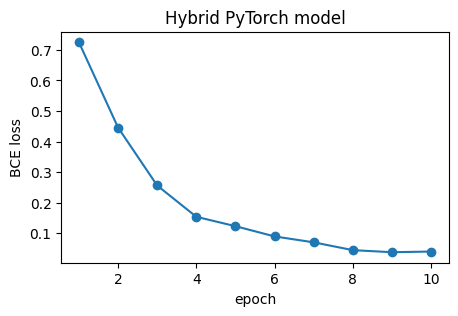

In [19]:
from torch.utils.data import DataLoader, TensorDataset

loader = DataLoader(TensorDataset(Xi_t, yi_t), batch_size=10, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))
opt = torch.optim.Adam(model.parameters(), lr=0.1)
loss_fn = nn.BCEWithLogitsLoss()

epoch_loss = []
for epoch in range(10):
    model.train(); total = 0.0
    for xb, yb in loader:
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
        total += loss.item() * len(xb)
    epoch_loss.append(total / len(Xi_t))
    print(f"epoch {epoch + 1:2d}  loss {epoch_loss[-1]:.4f}")

model.eval()
with torch.no_grad():
    acc = ((model(Xi_t) > 0).float() == yi_t).float().mean().item()
print("training accuracy:", acc)

plt.figure(figsize=(5, 3)); plt.plot(range(1, 11), epoch_loss, "o-")
plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.title("Hybrid PyTorch model");

## 9. Saving and loading models

* QML estimators (`QSVC`, `VQC`, `VQR`, `NeuralNetworkClassifier`/`Regressor`, …) inherit from [`SerializableModelMixin`](https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.algorithms.SerializableModelMixin.html) ([Saving and Loading tutorial](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/09_saving_and_loading_models.html)).
  * Save with **`model.to_dill(path)`** and load with **`Class.from_dill(path)`**.
  * The old names `save()`/`load()` are deprecated since version 0.9.0.
  * The file contains the whole object, including the primitive instance. Only load files from trusted sources.
* The hybrid PyTorch model is an ordinary `nn.Module`. The standard `state_dict` workflow applies, and the `TorchConnector` weights are part of the state dict.

In [20]:
import os, tempfile

tmpdir = tempfile.mkdtemp()
vqc_path = os.path.join(tmpdir, "vqc.dill")
qsvc_path = os.path.join(tmpdir, "qsvc.dill")

vqc.to_dill(vqc_path)
qsvc.to_dill(qsvc_path)

vqc_loaded = VQC.from_dill(vqc_path)
qsvc_loaded = QSVC.from_dill(qsvc_path)
print("VQC  predictions identical:", np.array_equal(vqc.predict(Xm_te), vqc_loaded.predict(Xm_te)))
print("QSVC predictions identical:", np.array_equal(qsvc.predict(X_test), qsvc_loaded.predict(X_test)))

# warm_start: continue training a loaded VQC from its saved weights
vqc_loaded.warm_start = True
vqc_loaded.optimizer = COBYLA(maxiter=10)
vqc_loaded.fit(Xm_tr, ym_tr)
print("VQC after 10 more iterations, test acc:", vqc_loaded.score(Xm_te, ym_te))

VQC  predictions identical: True


QSVC predictions identical: True


VQC after 10 more iterations, test acc: 0.8


In [21]:
torch_path = os.path.join(tmpdir, "hybrid.pt")
torch.save(model.state_dict(), torch_path)

model2 = HybridNet(hyb_qnn)
model2.load_state_dict(torch.load(torch_path))
model2.eval()
with torch.no_grad():
    print("hybrid outputs identical:", torch.allclose(model(Xi_t), model2(Xi_t)))
print("state_dict keys:", list(model.state_dict().keys()))

hybrid outputs identical: True
state_dict keys: ['pre.weight', 'pre.bias', 'q.weight', 'q._weights', 'post.weight', 'post.bias']


## Summary

* **Feature maps** (`zz_feature_map`, `z_feature_map`) encode classical data into quantum states. In Qiskit 2.x, use the function forms.
* **Quantum kernels**: `FidelityQuantumKernel` (any V2 sampler, through `ComputeUncompute`) or the exact `FidelityStatevectorKernel`. Use them with `QSVC` or with a precomputed `SVC`. A trainable kernel with `QuantumKernelTrainer` tunes parameters of the feature map.
* **QNNs**: `EstimatorQNN` returns expectation values, and `SamplerQNN` returns probabilities. Both have `forward` and `backward`. With `input_gradients=True`, gradients also flow to the inputs.
* **High-level learners**: `VQC`, `VQR` and `NeuralNetworkClassifier`. A `callback(weights, loss)` records the training progress.
* **`TorchConnector`** puts a QNN inside a PyTorch model.
* **Saving models**: QML models use `to_dill`/`from_dill`. PyTorch models use `state_dict`.

## References

1. Tutorial: *Quantum Kernel Machine Learning*. https://qiskit-community.github.io/qiskit-machine-learning/tutorials/03_quantum_kernel.html
2. Tutorial: *Quantum Kernel Training for Machine Learning Applications*. https://qiskit-community.github.io/qiskit-machine-learning/tutorials/08_quantum_kernel_trainer.html
3. Tutorial: *Quantum Neural Networks*. https://qiskit-community.github.io/qiskit-machine-learning/tutorials/01_neural_networks.html
4. Tutorial: *Neural Network Classifier & Regressor*. https://qiskit-community.github.io/qiskit-machine-learning/tutorials/02_neural_network_classifier_and_regressor.html
5. Tutorial: *Torch Connector and Hybrid QNNs*. https://qiskit-community.github.io/qiskit-machine-learning/tutorials/05_torch_connector.html
6. Tutorial: *Saving, Loading Qiskit Machine Learning Models and Continuous Training*. https://qiskit-community.github.io/qiskit-machine-learning/tutorials/09_saving_and_loading_models.html
7. API: quantum kernels (`qiskit_machine_learning.kernels`). https://qiskit-community.github.io/qiskit-machine-learning/apidocs/qiskit_machine_learning.kernels.html
8. API: quantum neural networks (`qiskit_machine_learning.neural_networks`). https://qiskit-community.github.io/qiskit-machine-learning/apidocs/qiskit_machine_learning.neural_networks.html
9. API: QML primitives (`qiskit_machine_learning.primitives`). https://qiskit-community.github.io/qiskit-machine-learning/apidocs/qiskit_machine_learning.primitives.html
10. API: `QSVC`. https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.algorithms.QSVC.html
11. API: `VQC`. https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.algorithms.VQC.html
12. API: `VQR`. https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.algorithms.VQR.html
13. API: `NeuralNetworkClassifier`. https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.algorithms.NeuralNetworkClassifier.html
14. API: `TorchConnector`. https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.connectors.TorchConnector.html
15. API: `ad_hoc_data`. https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.datasets.ad_hoc_data.html
16. API: `qnn_circuit`. https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.circuit.library.qnn_circuit.html
17. API: `SerializableModelMixin`. https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.algorithms.SerializableModelMixin.html
18. Qiskit API: `zz_feature_map`. https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.zz_feature_map